# ME256 Homework 3: variational models for flexible structures

**Official statement:** [ME256 Homework 3 (2011)](https://mecheng.iisc.ac.in/suresh/me256/hw2011/homework3.html). This notebook paraphrases the assignment and develops runnable discrete models; consult the linked page for the full questions.

The assignment asks for variational models of an inextensible wire and cloth, plus examples involving inner products and structural optimization. The code below addresses the wire and cloth questions. The remaining modeling questions are left as study prompts rather than presented as completed solutions.

## Reproduction

Run with Python 3 and NumPy, SciPy, and Matplotlib. The notebook uses SciPy's SLSQP constrained optimizer.

## Wire: discrete model and solution outline

Divide a wire of length $L$ into $n$ equal segments of length $d=L/n$. Let $\theta_j$ be the direction angle of segment $j$. Starting from the moved endpoint $(L,L)$, reconstruct nodes by

$$x_j=x_{j+1}-d\cos\theta_j,\qquad y_j=y_{j+1}-d\sin\theta_j.$$

This angle parameterization enforces every segment length exactly. Minimize the Euclidean norm of all node displacements from the initial straight wire,

$$J(\theta)=\sqrt{\sum_{j=0}^{n}\left[(x_j-jd)^2+y_j^2\right]}.$$

The model uses exactly one angle per segment, matching the number of segments and avoiding unused decision variables.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize


In [2]:
def reconstruct_wire(segment_angles, length=1.0, endpoint_height=None):
    segment_count = len(segment_angles)
    segment_length = length / segment_count
    if endpoint_height is None:
        endpoint_height = length
    reference_x = np.linspace(0.0, length, segment_count + 1)
    x_coordinates = np.empty(segment_count + 1)
    y_coordinates = np.empty(segment_count + 1)
    x_coordinates[-1], y_coordinates[-1] = length, endpoint_height
    for segment_index in range(segment_count - 1, -1, -1):
        x_coordinates[segment_index] = x_coordinates[segment_index + 1] - segment_length * np.cos(segment_angles[segment_index])
        y_coordinates[segment_index] = y_coordinates[segment_index + 1] - segment_length * np.sin(segment_angles[segment_index])
    return reference_x, x_coordinates, y_coordinates

def wire_displacement(angle_values):
    reference_x, x_coordinates, y_coordinates = reconstruct_wire(angle_values)
    return np.sqrt(np.sum((x_coordinates - reference_x) ** 2 + y_coordinates ** 2))

def solve_wire(segment_count=40):
    result = minimize(wire_displacement, np.zeros(segment_count), method="SLSQP",
        bounds=[(0.0, 2.0 * np.pi)] * segment_count,
        options={"maxiter": 1000, "ftol": 1e-10})
    if not result.success:
        raise RuntimeError(f"Wire optimization failed: {result.message}")
    reference_x, x_coordinates, y_coordinates = reconstruct_wire(result.x)
    return result, reference_x, x_coordinates, y_coordinates


### vmso3 wire run

vmso3: converged=True; objective=4.34721270; iterations=107; start=(0.374920, 0.241259)


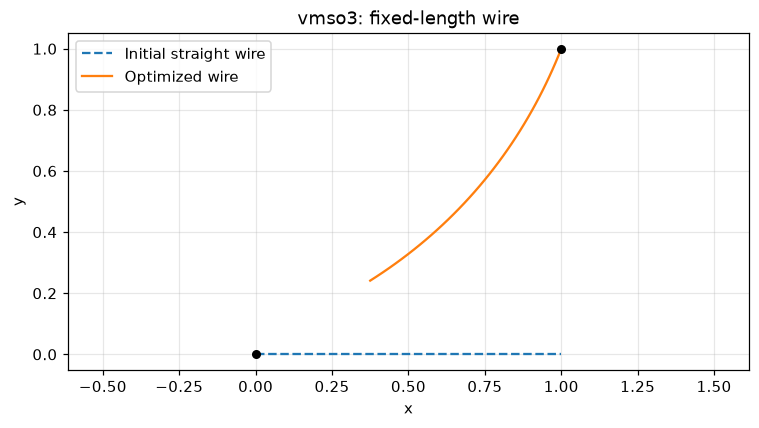

In [3]:
segment_count = 40
wire_result, reference_x, x_coordinates, y_coordinates = solve_wire(segment_count)
print(f"vmso3: converged={wire_result.success}; objective={wire_result.fun:.8f}; iterations={wire_result.nit}; start=({x_coordinates[0]:.6f}, {y_coordinates[0]:.6f})")
figure, axes = plt.subplots(figsize=(7, 4))
axes.plot(reference_x, np.zeros_like(reference_x), "--", label="Initial straight wire")
axes.plot(x_coordinates, y_coordinates, label="Optimized wire")
axes.scatter([0.0, 1.0], [0.0, 1.0], color="black", s=24, zorder=3)
axes.set(xlabel="x", ylabel="y", title=f"vmso3: fixed-length wire")
axes.set_aspect("equal", adjustable="datalim")
axes.grid(True, alpha=0.3)
axes.legend()
figure.tight_layout()
plt.show()


### vmso31 wire run

vmso31: converged=True; objective=4.34721270; iterations=107; start=(0.374920, 0.241259)


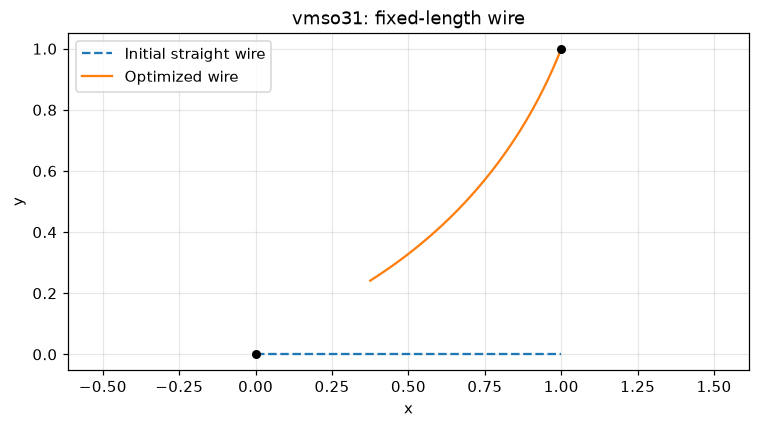

In [4]:
segment_count = 40
wire_result, reference_x, x_coordinates, y_coordinates = solve_wire(segment_count)
print(f"vmso31: converged={wire_result.success}; objective={wire_result.fun:.8f}; iterations={wire_result.nit}; start=({x_coordinates[0]:.6f}, {y_coordinates[0]:.6f})")
figure, axes = plt.subplots(figsize=(7, 4))
axes.plot(reference_x, np.zeros_like(reference_x), "--", label="Initial straight wire")
axes.plot(x_coordinates, y_coordinates, label="Optimized wire")
axes.scatter([0.0, 1.0], [0.0, 1.0], color="black", s=24, zorder=3)
axes.set(xlabel="x", ylabel="y", title=f"vmso31: fixed-length wire")
axes.set_aspect("equal", adjustable="datalim")
axes.grid(True, alpha=0.3)
axes.legend()
figure.tight_layout()
plt.show()


## Cloth: discrete model, source defects, and corrections

Represent mesh nodes by $\mathbf r_{ij}=(x_{ij},y_{ij},z_{ij})$. Minimize the sum of squared displacement from the initial flat grid, pinning the far corner at $(L,L,L)$. This squared objective has the same minimizer as the original square-root norm. Equality constraints keep mesh-edge lengths at their undeformed values.

### Why the original optimizer failed

The mesh has horizontal and vertical edge-length constraints. Each quadrilateral cell is triangulated by constraining one diagonal; constraining both diagonals would keep each cell planar and inhibit bending. A feasible folded initial mesh avoids the rank-deficient flat configuration.

The model constrains horizontal and vertical edges and uses one diagonal per cell so adjacent triangles can bend. It starts from a feasible gently folded mesh. The two mesh resolutions (`n=3` and `n=10`) are included.

In [5]:
def cloth_reference(mesh_subdivisions, length=1.0):
    grid_size = mesh_subdivisions + 1
    row_indices, column_indices = np.indices((grid_size, grid_size))
    return np.stack((column_indices * length / mesh_subdivisions,
                     row_indices * length / mesh_subdivisions,
                     np.zeros((grid_size, grid_size))), axis=-1)

def cloth_edge_constraints(mesh_subdivisions, length=1.0):
    grid_size = mesh_subdivisions + 1
    node_index = lambda row, column: row * grid_size + column
    edge_pairs, target_lengths = [], []
    segment_length = length / mesh_subdivisions
    for row in range(grid_size):
        for column in range(mesh_subdivisions):
            edge_pairs.append((node_index(row, column), node_index(row, column + 1)))
            target_lengths.append(segment_length)
    for row in range(mesh_subdivisions):
        for column in range(grid_size):
            edge_pairs.append((node_index(row, column), node_index(row + 1, column)))
            target_lengths.append(segment_length)
    for row in range(mesh_subdivisions):
        for column in range(mesh_subdivisions):
            edge_pairs.append((node_index(row, column), node_index(row + 1, column + 1)))
            target_lengths.append(np.sqrt(2.0) * segment_length)
    return np.asarray(edge_pairs, dtype=int), np.asarray(target_lengths)

def feasible_folded_cloth(mesh_subdivisions, length=1.0):
    grid_size = mesh_subdivisions + 1
    segment_length = length / mesh_subdivisions
    x_coordinates = np.linspace(0.0, length, grid_size)
    fold_angles = 0.25 * np.sin(2.0 * np.pi * (np.arange(mesh_subdivisions) + 0.5) / mesh_subdivisions)
    coordinates = np.empty((grid_size, grid_size, 3))
    coordinates[-1, :, 0] = x_coordinates
    coordinates[-1, :, 1] = length
    coordinates[-1, :, 2] = length
    for row in range(mesh_subdivisions - 1, -1, -1):
        coordinates[row, :, :] = coordinates[row + 1, :, :]
        coordinates[row, :, 1] -= segment_length * np.cos(fold_angles[row])
        coordinates[row, :, 2] -= segment_length * np.sin(fold_angles[row])
        coordinates[row, :, 0] = x_coordinates
    return coordinates

def solve_cloth(mesh_subdivisions, length=1.0):
    reference = cloth_reference(mesh_subdivisions, length)
    initial = feasible_folded_cloth(mesh_subdivisions, length)
    edge_pairs, target_lengths = cloth_edge_constraints(mesh_subdivisions, length)
    node_count = initial.shape[0] * initial.shape[1]
    fixed_node = node_count - 1
    fixed_values = np.array([length, length, length])
    free_coordinates = np.ones(node_count * 3, dtype=bool)
    free_coordinates[3 * fixed_node:3 * fixed_node + 3] = False
    reference_flat, initial_flat = reference.reshape(-1, 3), initial.reshape(-1, 3)
    initial_free = initial_flat.reshape(-1)[free_coordinates]
    def unpack(free_values):
        all_values = np.empty(node_count * 3)
        all_values[free_coordinates] = free_values
        all_values[~free_coordinates] = fixed_values
        return all_values.reshape(-1, 3)
    def objective(free_values):
        displacement = unpack(free_values) - reference_flat
        return np.sum(displacement ** 2)
    def objective_jacobian(free_values):
        return (2.0 * (unpack(free_values) - reference_flat)).reshape(-1)[free_coordinates]
    def edge_residuals(free_values):
        points = unpack(free_values)
        differences = points[edge_pairs[:, 0]] - points[edge_pairs[:, 1]]
        return np.sum(differences ** 2, axis=1) - target_lengths ** 2
    def edge_jacobian(free_values):
        points = unpack(free_values)
        differences = 2.0 * (points[edge_pairs[:, 0]] - points[edge_pairs[:, 1]])
        jacobian = np.zeros((len(edge_pairs), node_count * 3))
        rows, dimensions = np.arange(len(edge_pairs))[:, None], np.arange(3)[None, :]
        jacobian[rows, 3 * edge_pairs[:, 0, None] + dimensions] = differences
        jacobian[rows, 3 * edge_pairs[:, 1, None] + dimensions] = -differences
        return jacobian[:, free_coordinates]
    result = minimize(objective, initial_free, jac=objective_jacobian, method="SLSQP",
        constraints={"type": "eq", "fun": edge_residuals, "jac": edge_jacobian},
        options={"maxiter": 1000, "ftol": 1e-10})
    optimized_nodes = unpack(result.x).reshape(initial.shape)
    flat_nodes = optimized_nodes.reshape(-1, 3)
    edge_lengths = np.linalg.norm(flat_nodes[edge_pairs[:, 0]] - flat_nodes[edge_pairs[:, 1]], axis=1)
    maximum_edge_error = np.max(np.abs(edge_lengths - target_lengths))
    if not result.success or maximum_edge_error > 1e-7:
        raise RuntimeError(f"Cloth optimization failed: {result.message}; maximum edge-length error={maximum_edge_error:.3g}")
    return result, reference, initial, optimized_nodes, len(edge_pairs), maximum_edge_error

def plot_cloth(reference, optimized_nodes, title):
    mesh_subdivisions = reference.shape[0] - 1
    grid_size = mesh_subdivisions + 1
    faces = []
    for row in range(mesh_subdivisions):
        for column in range(mesh_subdivisions):
            upper_left = row * grid_size + column
            upper_right, lower_left = upper_left + 1, upper_left + grid_size
            lower_right = lower_left + 1
            faces.extend(((upper_left, upper_right, lower_right), (upper_left, lower_left, lower_right)))
    figure = plt.figure(figsize=(7, 5))
    axes = figure.add_subplot(111, projection="3d")
    flat = optimized_nodes.reshape(-1, 3)
    axes.plot_trisurf(flat[:, 0], flat[:, 1], flat[:, 2], triangles=np.asarray(faces),
        cmap="viridis", edgecolor="black", linewidth=0.35, alpha=0.9)
    axes.scatter(*optimized_nodes[-1, -1], color="crimson", s=32, label="Pinned corner")
    axes.set(xlabel="x", ylabel="y", zlabel="z", title=title)
    axes.set_box_aspect((1, 1, 1))
    axes.legend()
    figure.tight_layout()
    plt.show()


### Coarse cloth mesh (`vmso3`, 3 x 3 cells)

vmso3: converged=True; objective=5.25680759; iterations=32; edge constraints=33; maximum edge-length error=1.173e-11


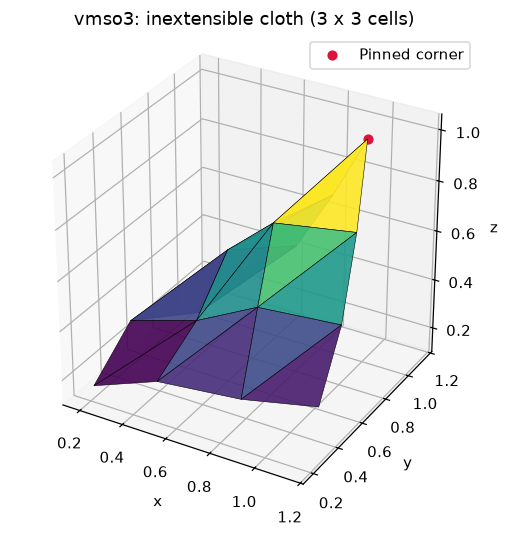

In [6]:
mesh_subdivisions = 3
cloth_result, reference, initial_nodes, optimized_nodes, edge_count, max_edge_error = solve_cloth(mesh_subdivisions)
print(f"vmso3: converged={cloth_result.success}; objective={cloth_result.fun:.8f}; iterations={cloth_result.nit}; edge constraints={edge_count}; maximum edge-length error={max_edge_error:.3e}")
plot_cloth(reference, optimized_nodes, f"vmso3: inextensible cloth ({mesh_subdivisions} x {mesh_subdivisions} cells)")


### Fine cloth mesh (`vmso31`, 10 x 10 cells)

vmso31: converged=True; objective=39.93244181; iterations=668; edge constraints=320; maximum edge-length error=6.823e-11


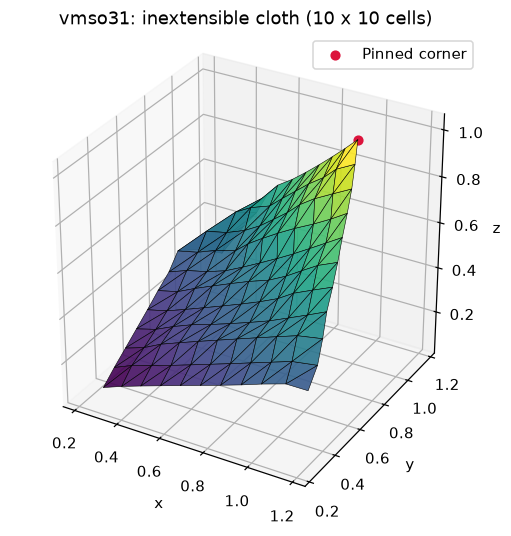

In [7]:
mesh_subdivisions = 10
cloth_result, reference, initial_nodes, optimized_nodes, edge_count, max_edge_error = solve_cloth(mesh_subdivisions)
print(f"vmso31: converged={cloth_result.success}; objective={cloth_result.fun:.8f}; iterations={cloth_result.nit}; edge constraints={edge_count}; maximum edge-length error={max_edge_error:.3e}")
plot_cloth(reference, optimized_nodes, f"vmso31: inextensible cloth ({mesh_subdivisions} x {mesh_subdivisions} cells)")


## Interpreting the runs

Both wire runs converge to the same discretized objective (about 4.3472), and both corrected cloth meshes satisfy edge-length constraints within the reported numerical tolerance. The plotted cloth is a numerical minimizer for this finite mesh, not a proof of existence, uniqueness, or convergence to a continuous variational solution. The two cloth meshes can differ because of discretization and local optimization.

The reported values are reproducible Python results for the stated discretizations and stopping criteria.

## Study prompts

- Identify the continuous configuration space suggested by the discrete angle/node variables. What norm does the objective approximate?
- Verify how the segment/edge equalities encode inextensibility. What changes as the mesh is refined?
- Develop an example whose functional uses an inner product, and formulate a structural-optimization problem in an appropriate function space.